<a href="https://colab.research.google.com/github/razokiyassine/Network-Intrusion-Detection/blob/main/TP2_DBSCAN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

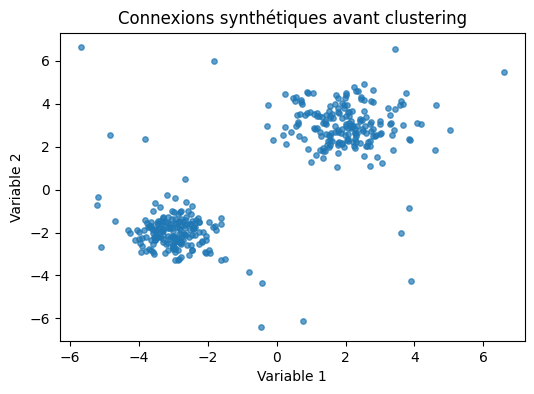

,eps,min_samples,clusters_hors_bruit,points_centraux,points_frontieres,bruit
0,0.15,4,3,328,10,42
1,0.15,8,3,264,50,66
2,0.30,4,2,359,1,20
3,0.30,8,2,344,16,20
4,0.50,4,2,366,3,11
5,0.50,8,2,362,6,12


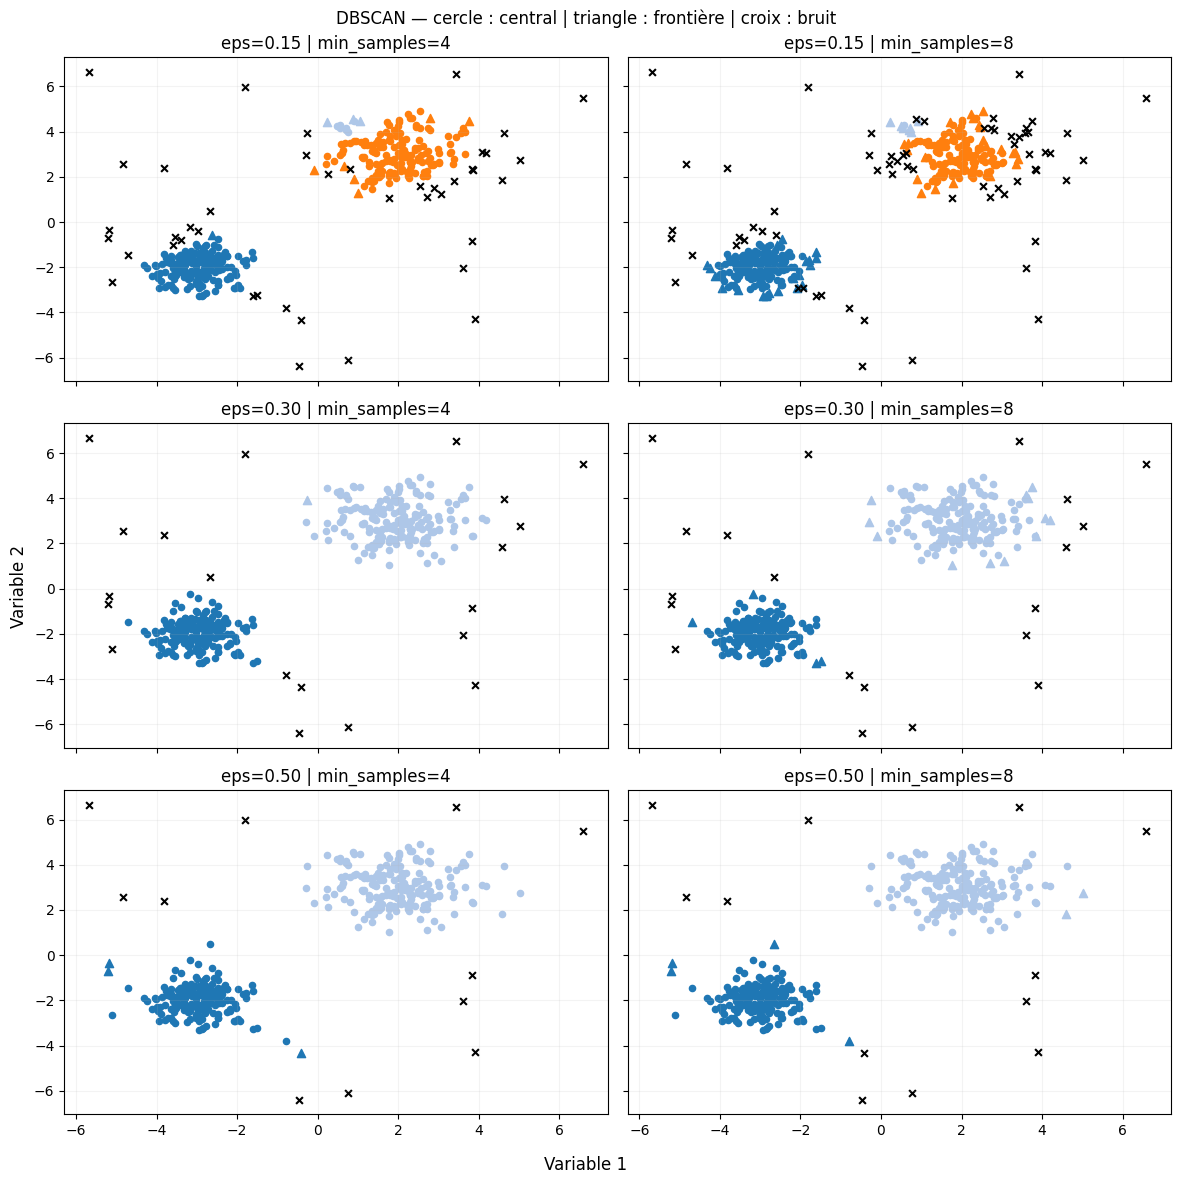

DBSCAN (eps=0.3, min_samples=4) : 20 points bruités
K-Means : 20 points les plus éloignés de leur centroïde
Points signalés par les deux méthodes : 19 sur 20


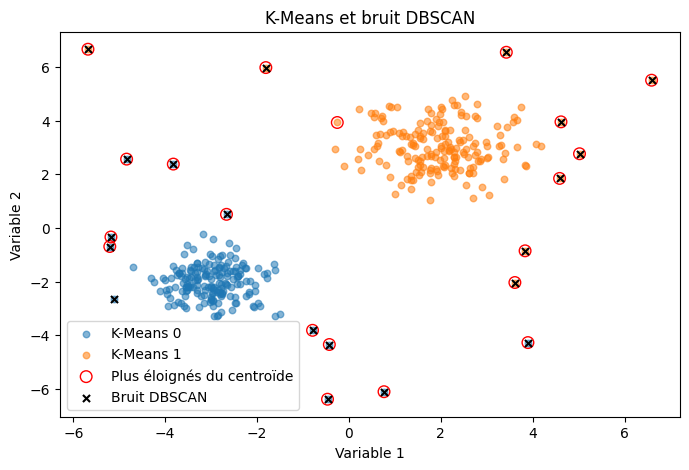

Points conservés pour la comparaison : 360/380
DBSCAN, hors bruit : 0.8154
K-Means, mêmes points : 0.8154
K-Means, tous les points : 0.7770


,index,variable_1,variable_2,label_dbscan,cluster_kmeans,distance_au_centroide,verification_soc
0,362,-5.682,6.659,-1,1,3.154,"Vérifier l'IP source, le poste et l'utilisateu..."
1,372,3.897,-4.275,-1,0,2.686,"Examiner la destination, le port et l'historiq..."
2,368,0.764,-6.107,-1,0,2.049,Recouper l'horodatage avec les événements d'au...


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.cluster import DBSCAN, KMeans
from sklearn.datasets import make_blobs
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

# 1. Générer les données de l'énoncé
rng = np.random.default_rng(42)

X_normal, _ = make_blobs(
    n_samples=360,
    centers=[(-3, -2), (2, 3)],
    cluster_std=[0.65, 0.85],
    random_state=42,
)
X_rare = rng.uniform(low=-7, high=7, size=(20, 2))
X = np.vstack([X_normal, X_rare])
X_scaled = StandardScaler().fit_transform(X)

plt.figure(figsize=(6, 4))
plt.scatter(X[:, 0], X[:, 1], s=15, alpha=.7)
plt.xlabel("Variable 1")
plt.ylabel("Variable 2")
plt.title("Connexions synthétiques avant clustering")
plt.show()

# 2. Tester les six configurations DBSCAN
models = {}
results = []

for eps in [0.15, 0.30, 0.50]:
    for ms in [4, 8]:
        model = DBSCAN(eps=eps, min_samples=ms).fit(X_scaled)
        models[(eps, ms)] = model
        labels = model.labels_
        n_noise = np.count_nonzero(labels == -1)
        n_core = len(model.core_sample_indices_)

        results.append({
            "eps": eps,
            "min_samples": ms,
            "clusters_hors_bruit": len(set(labels) - {-1}),
            "points_centraux": n_core,
            "points_frontieres": len(X) - n_noise - n_core,
            "bruit": n_noise,
        })

display(pd.DataFrame(results))

# 3. Visualiser les clusters, les points frontières et le bruit
fig, axes = plt.subplots(3, 2, figsize=(12, 12), sharex=True, sharey=True)

for ax, ((eps, ms), model) in zip(axes.flat, models.items()):
    labels = model.labels_
    core = np.zeros(len(X), dtype=bool)
    core[model.core_sample_indices_] = True

    for cluster in sorted(set(labels) - {-1}):
        group = labels == cluster
        color = plt.get_cmap("tab20")(cluster % 20)
        ax.scatter(*X[group & core].T, c=[color], s=20, marker="o")
        ax.scatter(*X[group & ~core].T, c=[color], s=35, marker="^")

    noise = labels == -1
    ax.scatter(*X[noise].T, c="black", s=24, marker="x")
    ax.set_title(f"eps={eps:.2f} | min_samples={ms}")
    ax.grid(alpha=.15)

fig.supxlabel("Variable 1")
fig.supylabel("Variable 2")
fig.suptitle("DBSCAN — cercle : central | triangle : frontière | croix : bruit")
plt.tight_layout()
plt.show()

# 4. Comparer DBSCAN et K-Means sur les mêmes données
# Configuration intermédiaire choisie comme exemple pour la comparaison.
eps, ms = 0.30, 4
db_labels = models[(eps, ms)].labels_
noise_ids = np.flatnonzero(db_labels == -1)

km = KMeans(n_clusters=2, n_init=10, random_state=42).fit(X_scaled)
km_labels = km.labels_
distances = km.transform(X_scaled).min(axis=1)

# Pour comparer à effectif égal, prendre autant de points éloignés
# dans K-Means que de points bruités dans DBSCAN.
n = len(noise_ids)
far_ids = np.argsort(-distances, kind="stable")[:n]
overlap = np.intersect1d(noise_ids, far_ids)

print(f"DBSCAN (eps={eps}, min_samples={ms}) : {n} points bruités")
print(f"K-Means : {len(far_ids)} points les plus éloignés de leur centroïde")
print(f"Points signalés par les deux méthodes : {len(overlap)} sur {n}")

fig, ax = plt.subplots(figsize=(8, 5))
for cluster in range(2):
    group = km_labels == cluster
    ax.scatter(*X[group].T, s=22, alpha=.55, label=f"K-Means {cluster}")

ax.scatter(*X[far_ids].T, facecolors="none", edgecolors="red", s=70,
           label="Plus éloignés du centroïde")
ax.scatter(*X[noise_ids].T, c="black", marker="x", s=26,
           label="Bruit DBSCAN")
ax.set(xlabel="Variable 1", ylabel="Variable 2", title="K-Means et bruit DBSCAN")
ax.legend()
plt.show()

# 5. Comparer les silhouettes sur le même sous-ensemble
def silhouette_valide(features, labels):
    n_clusters = np.unique(labels).size
    if 2 <= n_clusters < len(labels):
        return f"{silhouette_score(features, labels):.4f}"
    return "non calculable"

kept = db_labels != -1
print(f"Points conservés pour la comparaison : {kept.sum()}/{len(X)}")
print("DBSCAN, hors bruit :", silhouette_valide(X_scaled[kept], db_labels[kept]))
print("K-Means, mêmes points :", silhouette_valide(X_scaled[kept], km_labels[kept]))
print("K-Means, tous les points :", silhouette_valide(X_scaled, km_labels))

# 6. Extraire trois exemples de bruit et proposer des vérifications SOC
# Choisir parmi les points bruités les plus éloignés des centroïdes K-Means.
ranked_noise = noise_ids[np.argsort(-distances[noise_ids], kind="stable")]
sample_ids = ranked_noise[:3]

checks = [
    "Vérifier l'IP source, le poste et l'utilisateur dans les journaux DHCP, VPN et EDR.",
    "Examiner la destination, le port et l'historique des flux dans les logs réseau et DNS.",
    "Recouper l'horodatage avec les événements d'authentification et les alertes EDR.",
]

display(pd.DataFrame({
    "index": sample_ids,
    "variable_1": X[sample_ids, 0],
    "variable_2": X[sample_ids, 1],
    "label_dbscan": db_labels[sample_ids],
    "cluster_kmeans": km_labels[sample_ids],
    "distance_au_centroide": distances[sample_ids],
    "verification_soc": checks[:len(sample_ids)],
}).round(3))